In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import statistics as stats
import matplotlib.pylab as plt
import warnings
warnings.filterwarnings("ignore")


In [3]:
df=pd.read_csv("financial_regression.csv")

In [4]:
df.head()

,date,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,...,palladium high,palladium low,palladium close,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume
0,2010-01-14,114.49,115.14,114.42,114.93,115646960.0,0.72,46.26,46.520,46.22,...,45.02,43.86,44.84,364528.0,1.16,111.51,112.37,110.79,112.03,18305238.0
1,2010-01-15,114.73,114.84,113.20,113.64,212252769.0,1.64,46.46,46.550,45.65,...,45.76,44.40,45.76,442210.0,1.36,111.35,112.01,110.38,110.86,18000724.0
2,2010-01-18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2010-01-19,113.62,115.13,113.59,115.06,138671890.0,1.54,45.96,46.640,45.95,...,47.08,45.70,46.94,629150.0,1.38,110.95,111.75,110.83,111.52,10467927.0
4,2010-01-20,114.28,114.45,112.98,113.89,216330645.0,1.47,46.27,46.604,45.43,...,47.31,45.17,47.05,643198.0,2.14,109.97,110.05,108.46,108.94,17534231.0


In [5]:
pd.set_option("display.max_rows",None)

In [6]:
pd.set_option("display.width",None)
pd.set_option("display.max_colwidth",None)

In [7]:
df.head()

,date,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,...,palladium high,palladium low,palladium close,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume
0,2010-01-14,114.49,115.14,114.42,114.93,115646960.0,0.72,46.26,46.520,46.22,...,45.02,43.86,44.84,364528.0,1.16,111.51,112.37,110.79,112.03,18305238.0
1,2010-01-15,114.73,114.84,113.20,113.64,212252769.0,1.64,46.46,46.550,45.65,...,45.76,44.40,45.76,442210.0,1.36,111.35,112.01,110.38,110.86,18000724.0
2,2010-01-18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2010-01-19,113.62,115.13,113.59,115.06,138671890.0,1.54,45.96,46.640,45.95,...,47.08,45.70,46.94,629150.0,1.38,110.95,111.75,110.83,111.52,10467927.0
4,2010-01-20,114.28,114.45,112.98,113.89,216330645.0,1.47,46.27,46.604,45.43,...,47.31,45.17,47.05,643198.0,2.14,109.97,110.05,108.46,108.94,17534231.0


In [8]:
df.shape

(3904, 47)

In [9]:
df.columns

Index(['date', 'sp500 open', 'sp500 high', 'sp500 low', 'sp500 close',
       'sp500 volume', 'sp500 high-low', 'nasdaq open', 'nasdaq high',
       'nasdaq low', 'nasdaq close', 'nasdaq volume', 'nasdaq high-low',
       'us_rates_%', 'CPI', 'usd_chf', 'eur_usd', 'GDP', 'silver open',
       'silver high', 'silver low', 'silver close', 'silver volume',
       'silver high-low', 'oil open', 'oil high', 'oil low', 'oil close',
       'oil volume', 'oil high-low', 'platinum open', 'platinum high',
       'platinum low', 'platinum close', 'platinum volume',
       'platinum high-low', 'palladium open', 'palladium high',
       'palladium low', 'palladium close', 'palladium volume',
       'palladium high-low', 'gold open', 'gold high', 'gold low',
       'gold close', 'gold volume'],
      dtype='str')

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3904 entries, 0 to 3903
Data columns (total 47 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                3904 non-null   str    
 1   sp500 open          3719 non-null   float64
 2   sp500 high          3719 non-null   float64
 3   sp500 low           3719 non-null   float64
 4   sp500 close         3719 non-null   float64
 5   sp500 volume        3719 non-null   float64
 6   sp500 high-low      3719 non-null   float64
 7   nasdaq open         3719 non-null   float64
 8   nasdaq high         3719 non-null   float64
 9   nasdaq low          3719 non-null   float64
 10  nasdaq close        3719 non-null   float64
 11  nasdaq volume       3719 non-null   float64
 12  nasdaq high-low     3719 non-null   float64
 13  us_rates_%          176 non-null    float64
 14  CPI                 176 non-null    float64
 15  usd_chf             3694 non-null   float64
 16  eur_usd          

In [11]:
df.isnull().sum()

date                     0
sp500 open             185
sp500 high             185
sp500 low              185
sp500 close            185
sp500 volume           185
sp500 high-low         185
nasdaq open            185
nasdaq high            185
nasdaq low             185
nasdaq close           185
nasdaq volume          185
nasdaq high-low        185
us_rates_%            3728
CPI                   3728
usd_chf                210
eur_usd                210
GDP                   3847
silver open            185
silver high            185
silver low             185
silver close           185
silver volume          185
silver high-low        185
oil open               185
oil high               185
oil low                185
oil close              185
oil volume             185
oil high-low           185
platinum open          185
platinum high          185
platinum low           185
platinum close         185
platinum volume        185
platinum high-low      185
palladium open         185
p

In [12]:
(df.isnull().sum()/len(df))*100

date                   0.000000
sp500 open             4.738730
sp500 high             4.738730
sp500 low              4.738730
sp500 close            4.738730
sp500 volume           4.738730
sp500 high-low         4.738730
nasdaq open            4.738730
nasdaq high            4.738730
nasdaq low             4.738730
nasdaq close           4.738730
nasdaq volume          4.738730
nasdaq high-low        4.738730
us_rates_%            95.491803
CPI                   95.491803
usd_chf                5.379098
eur_usd                5.379098
GDP                   98.539959
silver open            4.738730
silver high            4.738730
silver low             4.738730
silver close           4.738730
silver volume          4.738730
silver high-low        4.738730
oil open               4.738730
oil high               4.738730
oil low                4.738730
oil close              4.738730
oil volume             4.738730
oil high-low           4.738730
platinum open          4.738730
platinum

In [13]:
df=df.drop(columns=["us_rates_%","CPI","GDP"])


In [14]:
df.ffill(inplace=True)

,date,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,...,palladium high,palladium low,palladium close,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume
0,2010-01-14,114.4900,115.1400,114.4200,114.93,115646960.0,0.7200,46.2600,46.5200,46.2200,...,45.0200,43.8600,44.8400,364528.0,1.1600,111.5100,112.3700,110.7900,112.0300,18305238.0
1,2010-01-15,114.7300,114.8400,113.2000,113.64,212252769.0,1.6400,46.4600,46.5500,45.6500,...,45.7600,44.4000,45.7600,442210.0,1.3600,111.3500,112.0100,110.3800,110.8600,18000724.0
2,2010-01-18,114.7300,114.8400,113.2000,113.64,212252769.0,1.6400,46.4600,46.5500,45.6500,...,45.7600,44.4000,45.7600,442210.0,1.3600,111.3500,112.0100,110.3800,110.8600,18000724.0
3,2010-01-19,113.6200,115.1300,113.5900,115.06,138671890.0,1.5400,45.9600,46.6400,45.9500,...,47.0800,45.7000,46.9400,629150.0,1.3800,110.9500,111.7500,110.8300,111.5200,10467927.0
4,2010-01-20,114.2800,114.4500,112.9800,113.89,216330645.0,1.4700,46.2700,46.6040,45.4300,...,47.3100,45.1700,47.0500,643198.0,2.1400,109.9700,110.0500,108.4600,108.9400,17534231.0
5,2010-01-21,113.9200,114.2700,111.5600,111.70,344747028.0,2.7100,46.0600,46.3500,45.3000,...,46.9800,45.0700,45.3000,388457.0,1.9100,108.4800,108.7800,106.6100,107.3700,25747831.0
6,2010-01-22,111.2000,111.7400,109.0900,109.21,345627282.0,2.6500,45.3400,45.4800,44.0400,...,44.3860,42.6000,43.3000,343595.0,1.7860,106.9300,107.6800,106.0100,107.1700,24209966.0
7,2010-01-25,110.2100,110.4100,109.4100,109.77,186751367.0,1.0000,44.3900,44.6000,44.1200,...,44.4200,43.4300,44.3600,184431.0,0.9900,107.4400,107.7200,107.0700,107.4800,13170442.0
8,2010-01-26,109.3400,110.4700,109.0400,109.31,210788669.0,1.4300,44.2800,44.8900,44.0500,...,43.1000,42.3800,42.7500,338167.0,0.7200,106.8700,107.9900,106.7500,107.5600,12274165.0
9,2010-01-27,109.1700,110.0800,108.3300,109.83,271482263.0,1.7500,44.2900,44.8500,44.0100,...,42.4400,40.9300,41.3400,419800.0,1.5100,107.5300,108.8000,106.1600,106.5280,18991219.0


In [15]:
df.isnull().sum()

date                  0
sp500 open            0
sp500 high            0
sp500 low             0
sp500 close           0
sp500 volume          0
sp500 high-low        0
nasdaq open           0
nasdaq high           0
nasdaq low            0
nasdaq close          0
nasdaq volume         0
nasdaq high-low       0
usd_chf               0
eur_usd               0
silver open           0
silver high           0
silver low            0
silver close          0
silver volume         0
silver high-low       0
oil open              0
oil high              0
oil low               0
oil close             0
oil volume            0
oil high-low          0
platinum open         0
platinum high         0
platinum low          0
platinum close        0
platinum volume       0
platinum high-low     0
palladium open        0
palladium high        0
palladium low         0
palladium close       0
palladium volume      0
palladium high-low    0
gold open             0
gold high             0
gold low        

In [16]:
df["date"]=pd.to_datetime(df["date"])

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3904 entries, 0 to 3903
Data columns (total 44 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   date                3904 non-null   datetime64[us]
 1   sp500 open          3904 non-null   float64       
 2   sp500 high          3904 non-null   float64       
 3   sp500 low           3904 non-null   float64       
 4   sp500 close         3904 non-null   float64       
 5   sp500 volume        3904 non-null   float64       
 6   sp500 high-low      3904 non-null   float64       
 7   nasdaq open         3904 non-null   float64       
 8   nasdaq high         3904 non-null   float64       
 9   nasdaq low          3904 non-null   float64       
 10  nasdaq close        3904 non-null   float64       
 11  nasdaq volume       3904 non-null   float64       
 12  nasdaq high-low     3904 non-null   float64       
 13  usd_chf             3904 non-null   float64       
 14  eur

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df.describe()

,date,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,...,palladium high,palladium low,palladium close,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume
count,3904,3904.000000,3904.000000,3904.000000,3904.000000,3.904000e+03,3904.000000,3904.000000,3904.000000,3904.000000,...,3904.000000,3904.000000,3904.000000,3.904000e+03,3904.000000,3904.000000,3904.000000,3904.000000,3904.000000,3.904000e+03
mean,2017-06-03 14:57:02.950819,268.682987,270.122713,267.117416,268.733058,1.122172e+08,3.005297,181.315445,182.601612,179.909807,...,110.178456,107.932564,109.068986,7.102971e+04,2.245892,145.426749,146.072012,144.737571,145.427769,9.616390e+06
min,2010-01-14 00:00:00,103.110000,103.420000,101.130000,102.200000,1.708170e+05,0.300000,42.670000,42.821500,41.550000,...,40.550000,38.490000,40.090000,3.157000e+03,0.230000,100.920000,100.990000,100.232600,100.500000,1.436508e+06
25%,2013-09-24 18:00:00,169.752500,170.177500,169.040000,169.670000,6.674730e+07,1.270000,78.705000,79.180000,78.322500,...,69.387500,68.285000,68.802500,2.082100e+04,0.870000,120.537500,121.020000,120.150000,120.570000,5.789278e+06
50%,2017-06-03 12:00:00,240.910000,241.965000,239.310000,240.580000,9.254360e+07,2.075000,138.590000,139.250000,137.935000,...,83.900000,82.620000,83.180000,3.812500e+04,1.410000,137.615000,138.137050,137.010000,137.725000,8.059978e+06
75%,2021-02-10 06:00:00,373.637500,377.400000,370.972500,373.942500,1.362987e+08,3.780000,283.435000,286.990000,280.890000,...,143.595075,140.308775,141.710000,8.301775e+04,2.685700,167.762500,168.391250,167.030025,167.822500,1.152169e+07
max,2024-10-23 00:00:00,585.910000,586.120000,582.580000,584.590000,7.095045e+08,22.960000,503.070000,503.520000,498.390000,...,298.210000,277.000100,295.000000,1.199042e+06,45.392300,253.080000,253.940000,252.520000,253.930000,9.369811e+07
std,NaN,121.301869,121.950782,120.593032,121.329094,6.868014e+07,2.647785,122.407022,123.324716,121.377740,...,58.434174,56.867084,57.675993,9.710389e+04,2.531757,29.577059,29.725640,29.393772,29.581290,6.138491e+06


In [20]:
df["date"]=pd.to_datetime(df["date"])

In [21]:
df["Day"]=df["date"].dt.day
df["MOnth"]=df["date"].dt.month
df["Year"]=df["date"].dt.year

In [22]:
df.head()

,date,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,...,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume,Day,MOnth,Year
0,2010-01-14,114.49,115.14,114.42,114.93,115646960.0,0.72,46.26,46.520,46.22,...,364528.0,1.16,111.51,112.37,110.79,112.03,18305238.0,14,1,2010
1,2010-01-15,114.73,114.84,113.20,113.64,212252769.0,1.64,46.46,46.550,45.65,...,442210.0,1.36,111.35,112.01,110.38,110.86,18000724.0,15,1,2010
2,2010-01-18,114.73,114.84,113.20,113.64,212252769.0,1.64,46.46,46.550,45.65,...,442210.0,1.36,111.35,112.01,110.38,110.86,18000724.0,18,1,2010
3,2010-01-19,113.62,115.13,113.59,115.06,138671890.0,1.54,45.96,46.640,45.95,...,629150.0,1.38,110.95,111.75,110.83,111.52,10467927.0,19,1,2010
4,2010-01-20,114.28,114.45,112.98,113.89,216330645.0,1.47,46.27,46.604,45.43,...,643198.0,2.14,109.97,110.05,108.46,108.94,17534231.0,20,1,2010


In [23]:
del df["date"]

In [24]:
df.head()

,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,nasdaq close,...,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume,Day,MOnth,Year
0,114.49,115.14,114.42,114.93,115646960.0,0.72,46.26,46.520,46.22,46.39,...,364528.0,1.16,111.51,112.37,110.79,112.03,18305238.0,14,1,2010
1,114.73,114.84,113.20,113.64,212252769.0,1.64,46.46,46.550,45.65,45.85,...,442210.0,1.36,111.35,112.01,110.38,110.86,18000724.0,15,1,2010
2,114.73,114.84,113.20,113.64,212252769.0,1.64,46.46,46.550,45.65,45.85,...,442210.0,1.36,111.35,112.01,110.38,110.86,18000724.0,18,1,2010
3,113.62,115.13,113.59,115.06,138671890.0,1.54,45.96,46.640,45.95,46.59,...,629150.0,1.38,110.95,111.75,110.83,111.52,10467927.0,19,1,2010
4,114.28,114.45,112.98,113.89,216330645.0,1.47,46.27,46.604,45.43,45.92,...,643198.0,2.14,109.97,110.05,108.46,108.94,17534231.0,20,1,2010


In [25]:
df.dtypes

sp500 open            float64
sp500 high            float64
sp500 low             float64
sp500 close           float64
sp500 volume          float64
sp500 high-low        float64
nasdaq open           float64
nasdaq high           float64
nasdaq low            float64
nasdaq close          float64
nasdaq volume         float64
nasdaq high-low       float64
usd_chf               float64
eur_usd               float64
silver open           float64
silver high           float64
silver low            float64
silver close          float64
silver volume         float64
silver high-low       float64
oil open              float64
oil high              float64
oil low               float64
oil close             float64
oil volume            float64
oil high-low          float64
platinum open         float64
platinum high         float64
platinum low          float64
platinum close        float64
platinum volume       float64
platinum high-low     float64
palladium open        float64
palladium 

In [26]:
num_cols=df.corr(numeric_only=True)
print(len(num_cols))

46


## Visulization

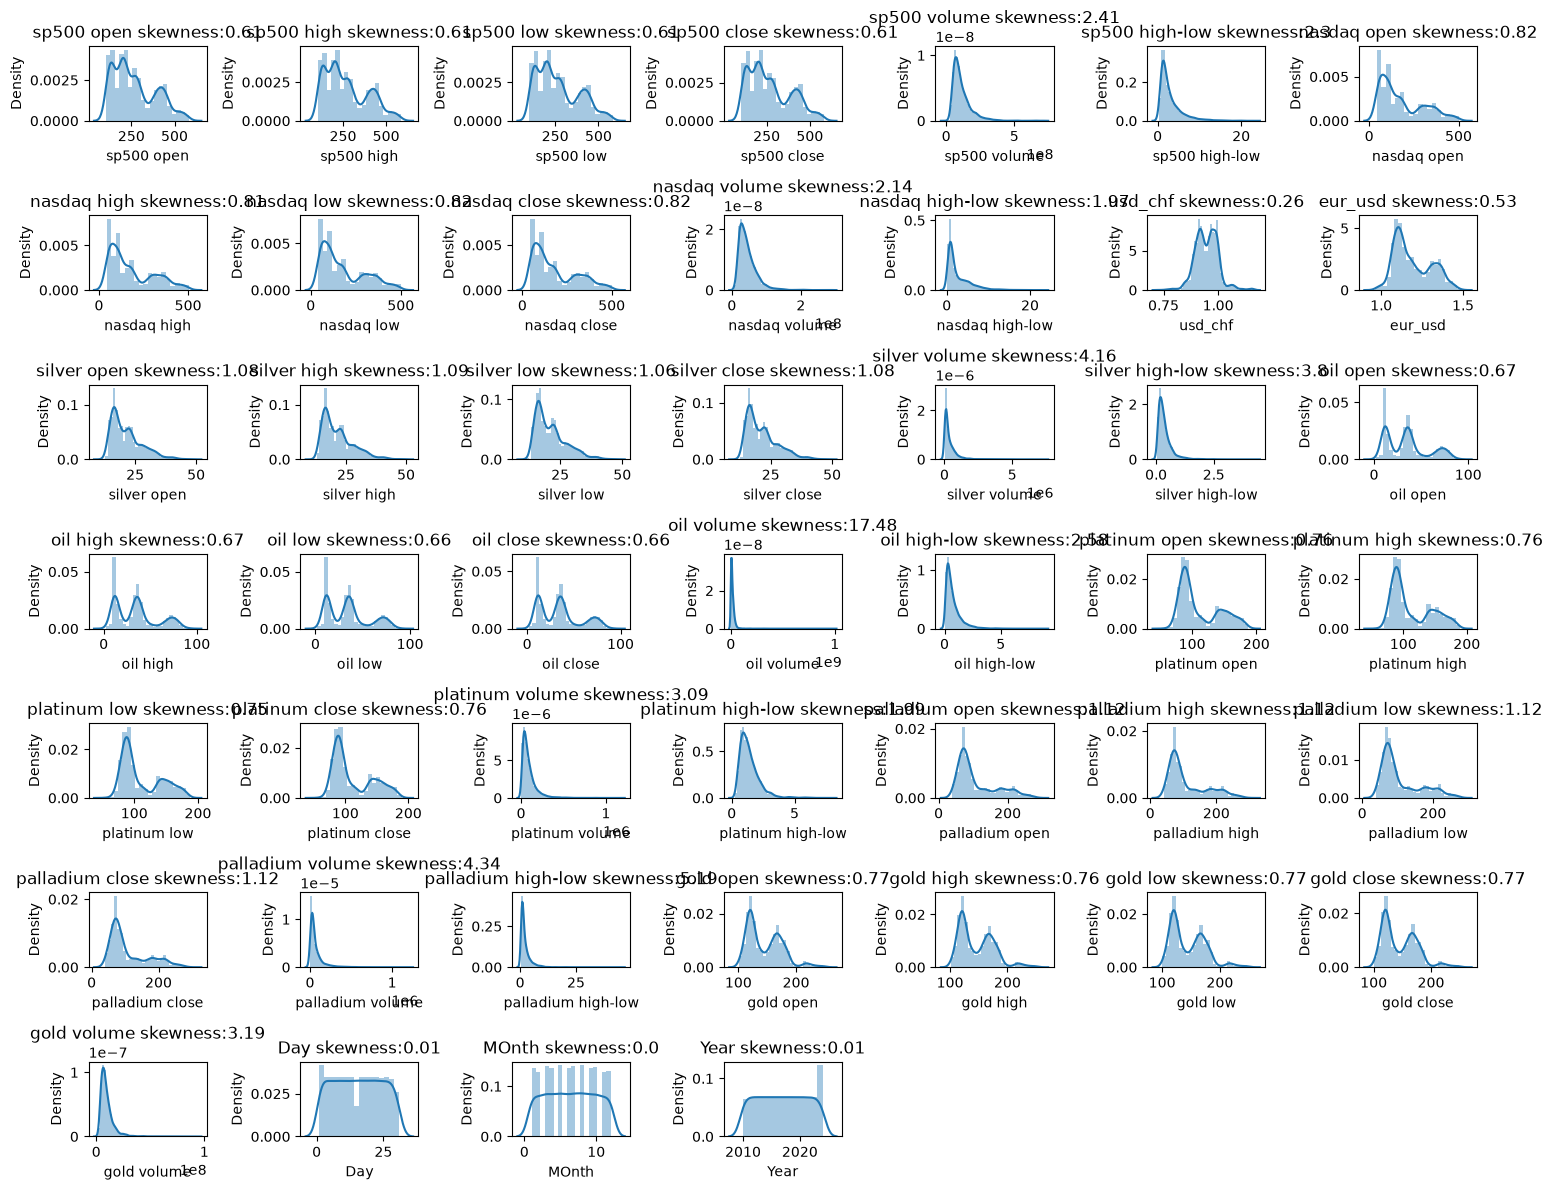

In [27]:
t=1
plt.figure(figsize=(15,12))
for i in num_cols:
    plt.subplot(7,7,t)
    sns.distplot(df[i])
    plt.title(f'{i} skewness:{round(df[i].skew(),2)}')
    t+=1
plt.tight_layout()
plt.show()

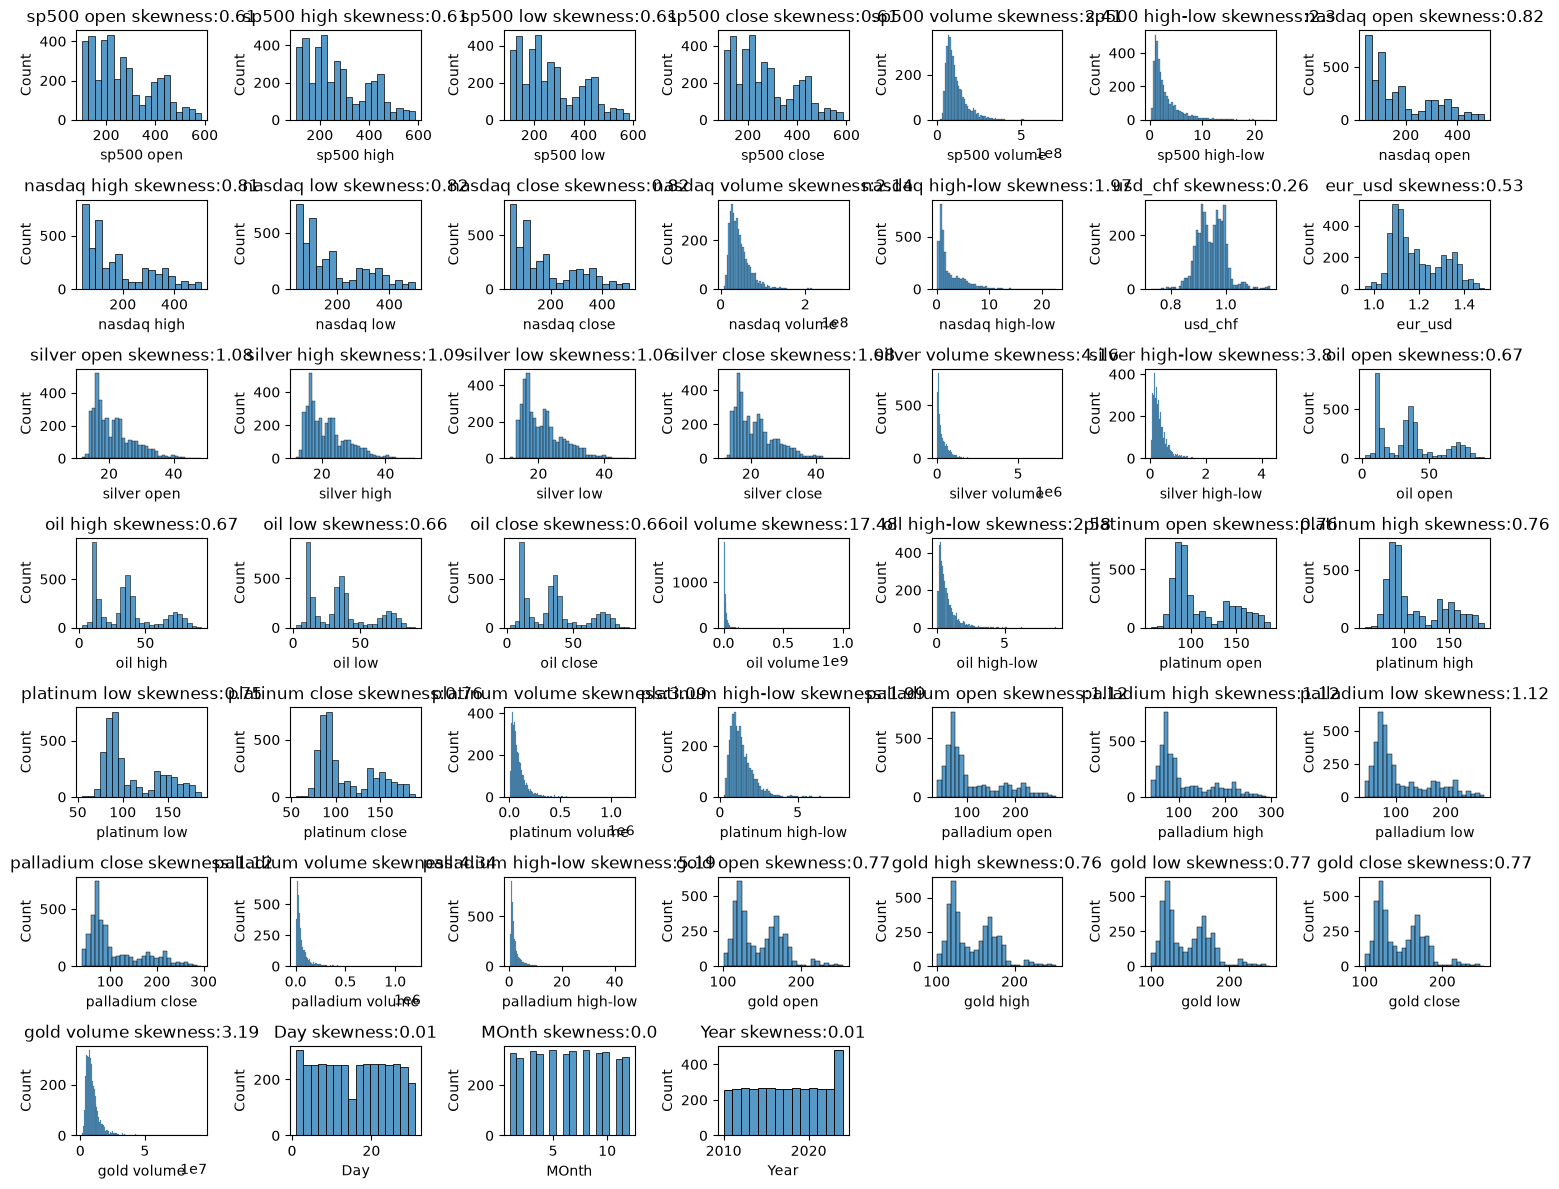

In [28]:
t=1
plt.figure(figsize=(15,12))
for i in num_cols:
    plt.subplot(7,7,t)
    sns.histplot(df[i])
    plt.title(f'{i} skewness:{round(df[i].skew(),2)}')
    t+=1
plt.tight_layout()
plt.show()

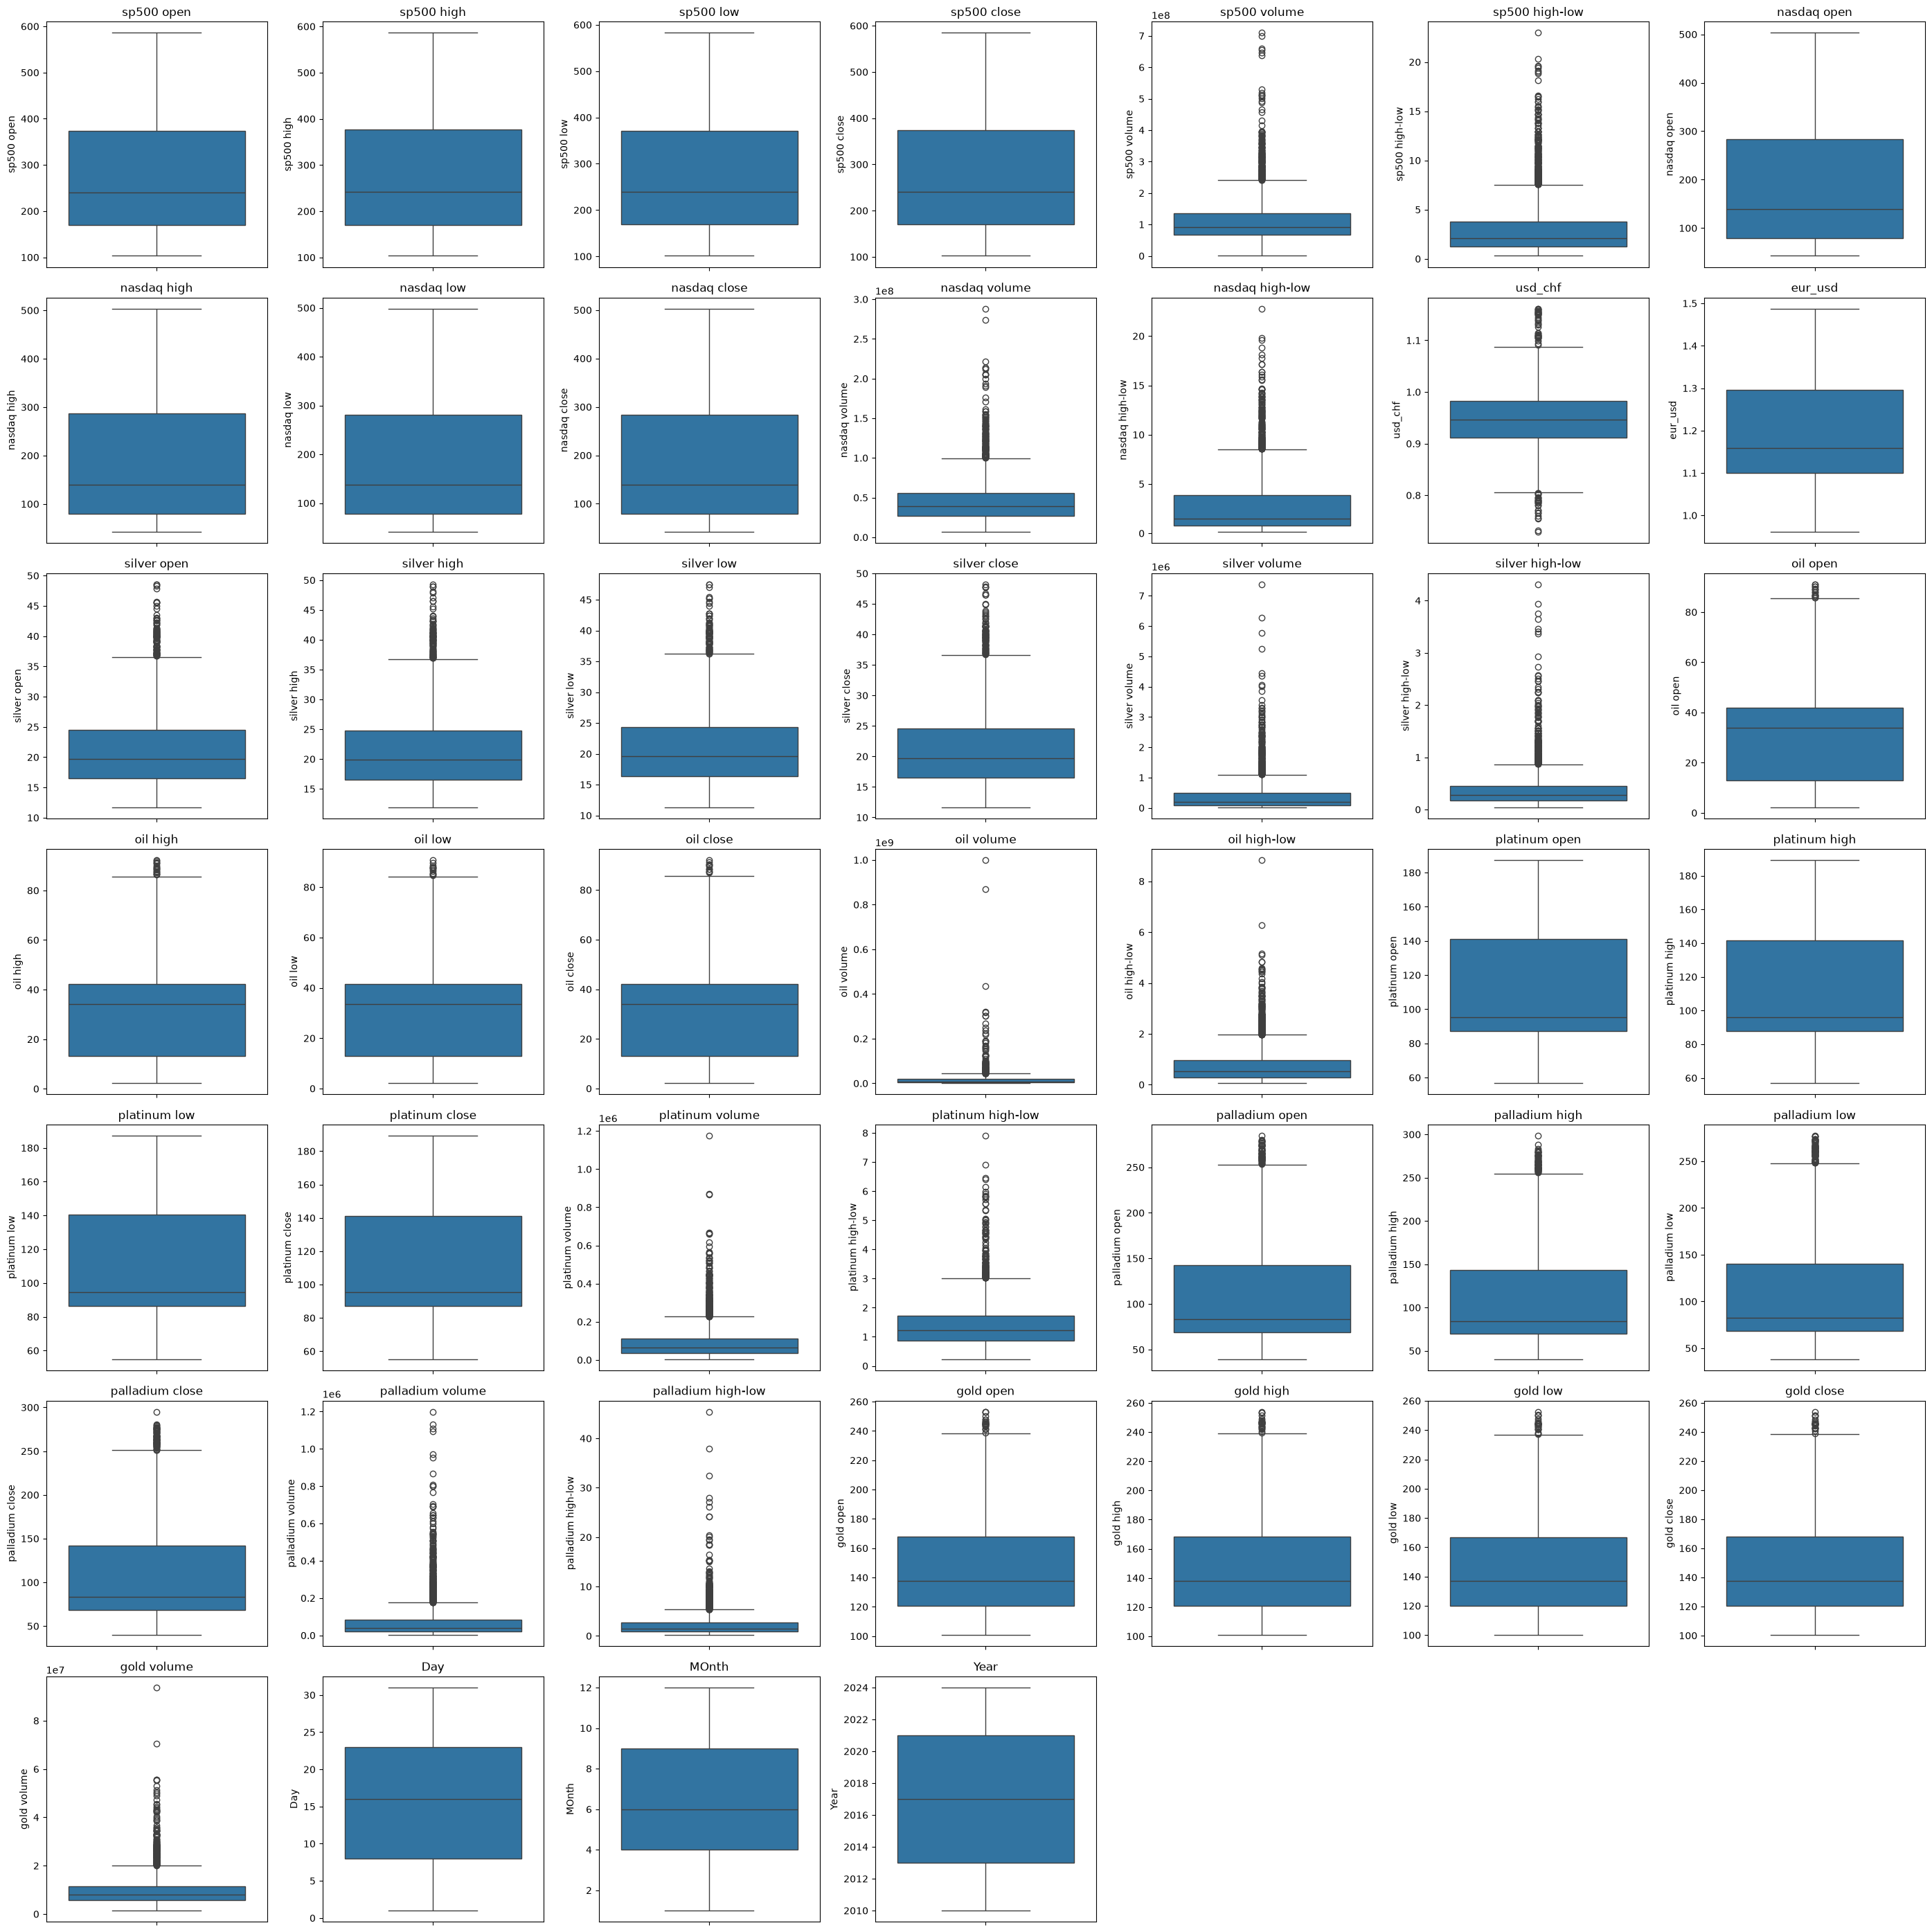

In [29]:
# box plot for numericas figrures
plt.figure(figsize=(28,28))
for t, col in enumerate (num_cols,1):
    plt.subplot(7,7,t)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

### Encoding 

In [30]:
# Display all columns of the DataFrame without hiding any.
# Display all columns in the output
pd.set_option('display.max_columns', None)

# Display the first five rows of the dataset
df.head()

,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,nasdaq close,nasdaq volume,nasdaq high-low,usd_chf,eur_usd,silver open,silver high,silver low,silver close,silver volume,silver high-low,oil open,oil high,oil low,oil close,oil volume,oil high-low,platinum open,platinum high,platinum low,platinum close,platinum volume,platinum high-low,palladium open,palladium high,palladium low,palladium close,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume,Day,MOnth,Year
0,114.49,115.14,114.42,114.93,115646960.0,0.72,46.26,46.520,46.22,46.39,75209000.0,0.300,1.0206,1.4478,18.58,18.70,18.45,18.66,69804.0,0.25,39.30,39.4400,38.88,39.06,8575821.0,0.5600,160.13,161.85,159.7200,161.45,228500.0,2.1300,43.93,45.02,43.86,44.84,364528.0,1.16,111.51,112.37,110.79,112.03,18305238.0,14,1,2010
1,114.73,114.84,113.20,113.64,212252769.0,1.64,46.46,46.550,45.65,45.85,126849300.0,0.900,1.0264,1.4376,18.54,18.54,18.36,18.41,205106.0,0.18,38.97,39.0200,38.28,38.40,12615299.0,0.7400,160.68,161.25,159.5000,160.25,189900.0,1.7500,45.18,45.76,44.40,45.76,442210.0,1.36,111.35,112.01,110.38,110.86,18000724.0,15,1,2010
2,114.73,114.84,113.20,113.64,212252769.0,1.64,46.46,46.550,45.65,45.85,126849300.0,0.900,1.0264,1.4376,18.54,18.54,18.36,18.41,205106.0,0.18,38.97,39.0200,38.28,38.40,12615299.0,0.7400,160.68,161.25,159.5000,160.25,189900.0,1.7500,45.18,45.76,44.40,45.76,442210.0,1.36,111.35,112.01,110.38,110.86,18000724.0,18,1,2010
3,113.62,115.13,113.59,115.06,138671890.0,1.54,45.96,46.640,45.95,46.59,84388200.0,0.690,1.0340,1.4269,18.53,18.79,18.50,18.79,130552.0,0.29,38.07,38.9499,38.03,38.93,8180157.0,0.9199,162.23,165.20,162.1722,165.12,295900.0,3.0278,46.01,47.08,45.70,46.94,629150.0,1.38,110.95,111.75,110.83,111.52,10467927.0,19,1,2010
4,114.28,114.45,112.98,113.89,216330645.0,1.47,46.27,46.604,45.43,45.92,145680000.0,1.174,1.0453,1.4094,18.31,18.31,17.78,17.86,230907.0,0.53,38.23,38.3500,37.88,37.89,11438685.0,0.4700,163.51,163.51,159.0900,163.22,438200.0,4.4200,46.59,47.31,45.17,47.05,643198.0,2.14,109.97,110.05,108.46,108.94,17534231.0,20,1,2010


In [31]:
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = df.drop('gold close', axis=1)      # Features
y = df['gold close']                   # Target variable

# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [32]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(3123, 45)
(781, 45)
(3123,)
(781,)


### Linear regression model

In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error

lin = LinearRegression()                          # Create a Linear Regression model
model_dt = lin.fit(X_train, y_train)              # Train (fit) the model using the training data

ytrain_pred = model_dt.predict(X_train)           # Predict the target values for the training dataset
y_pred = model_dt.predict(X_test)                 # Predict the target values for the testing dataset

# Evaluate the model using R² Score and RMSE
print("Linear Regression:")
print("Training R2 Score:", r2_score(y_train, ytrain_pred))
print("Training RMSE:", np.sqrt(mean_squared_error(y_train, ytrain_pred)))
print("Testing R2 Score:", r2_score(y_test, y_pred))
print("Testing RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

Linear Regression:
Training R2 Score: 0.9999088515927462
Training RMSE: 0.2829348402598579
Testing R2 Score: 0.9999203422279666
Testing RMSE: 0.2616711103546731


In [34]:
!pip install xgboost


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
from xgboost import XGBRegressor

# Create an XGBoost Regressor model with specified hyperparameters
xgb = XGBRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)

# Train model
xgb.fit(X_train, y_train)

# Predict
y_train_pred = xgb.predict(X_train)
y_test_pred = xgb.predict(X_test)

# Evaluate
print("XGBoost:")
print("Training R2:", r2_score(y_train, y_train_pred))
print("Testing R2:", r2_score(y_test, y_test_pred))
print("Testing RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))

XGBoost:
Training R2: 0.9999732210998072
Testing R2: 0.9995742393984448
Testing RMSE: 0.6049569006042796


In [36]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create KNN Regressor
knn = KNeighborsRegressor(
    n_neighbors=5,
    weights='uniform',
    metric='minkowski'
)

# Train the model
knn.fit(X_train_scaled, y_train)

# Predictions
y_train_pred = knn.predict(X_train_scaled)
y_test_pred = knn.predict(X_test_scaled)

# Performance
print("KNN Regression Performance")
print("Training R2 Score:", round(r2_score(y_train, y_train_pred), 4))
print("Training RMSE:", round(np.sqrt(mean_squared_error(y_train, y_train_pred)), 4))
print("Testing R2 Score:", round(r2_score(y_test, y_test_pred), 4))
print("Testing RMSE:", round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 4))

KNN Regression Performance
Training R2 Score: 0.9948
Training RMSE: 2.1399
Testing R2 Score: 0.9926
Testing RMSE: 2.5242


In [37]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Create a Random Forest Regressor model
rf = RandomForestRegressor(
    n_estimators=100,     # Number of decision trees
    random_state=42       # Ensures reproducible results
)

# Train the model
rf.fit(X_train, y_train)

# Predict on training and testing datasets
y_train_pred = rf.predict(X_train)
y_test_pred = rf.predict(X_test)

# Evaluate the model
print("Random Forest Regressor")

print("Training R2 Score:", r2_score(y_train, y_train_pred))
print("Testing R2 Score:", r2_score(y_test, y_test_pred))
print("MAE:", mean_absolute_error(y_test, y_test_pred))
print("MSE:", mean_squared_error(y_test, y_test_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))

Random Forest Regressor
Training R2 Score: 0.9999443967280885
Testing R2 Score: 0.9996471052841297
MAE: 0.35748072983354573
MSE: 0.30333921223774724
RMSE: 0.5507623918149707


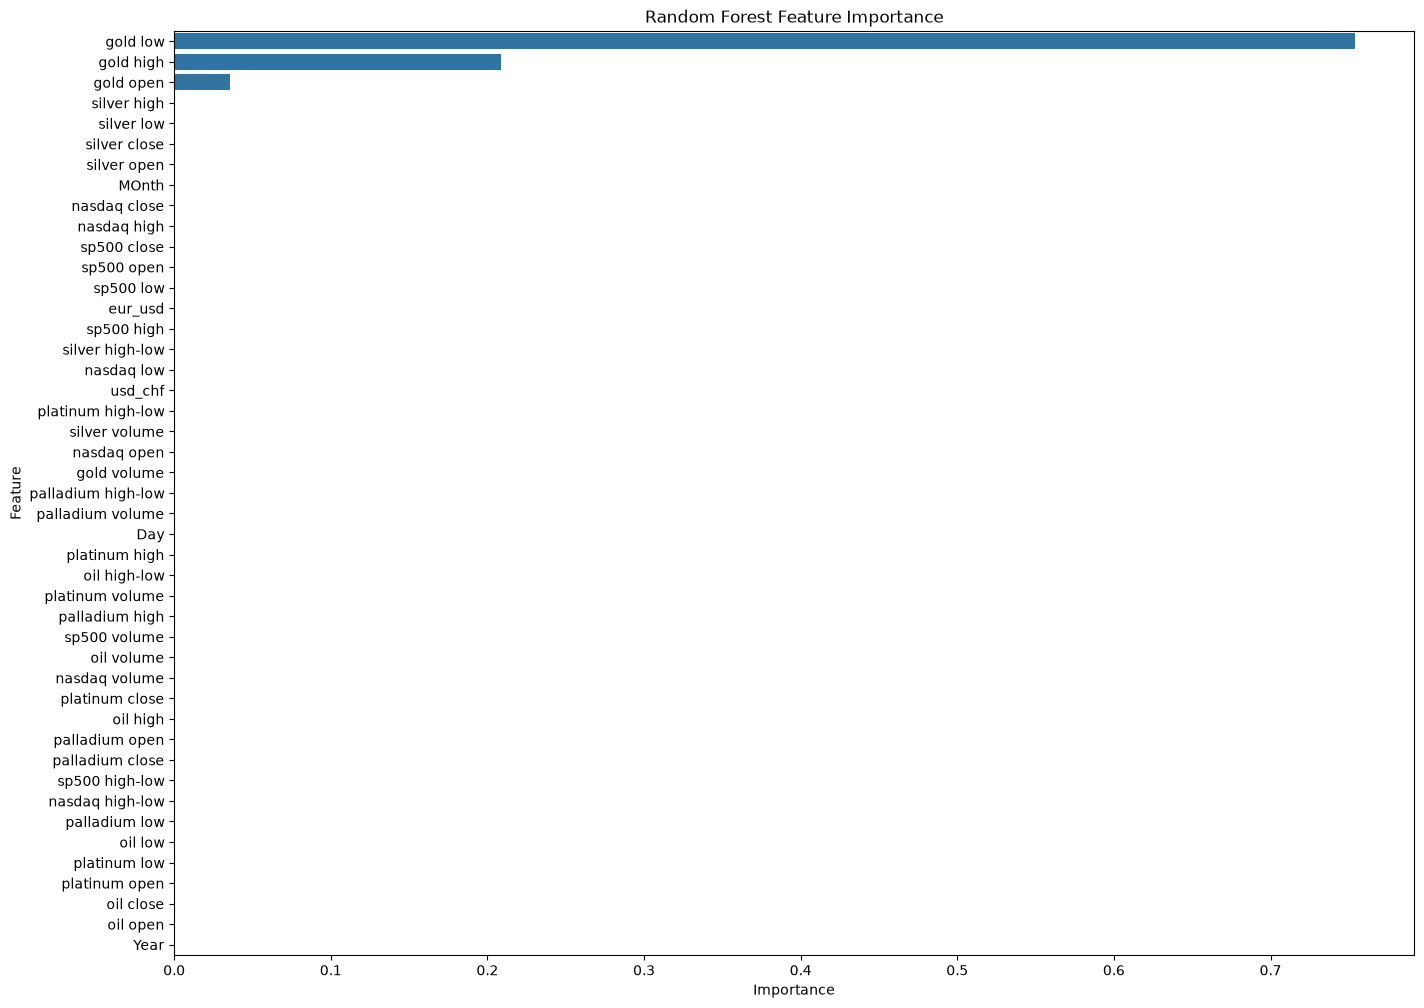

In [38]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

importance = importance.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(16, 12))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.show()

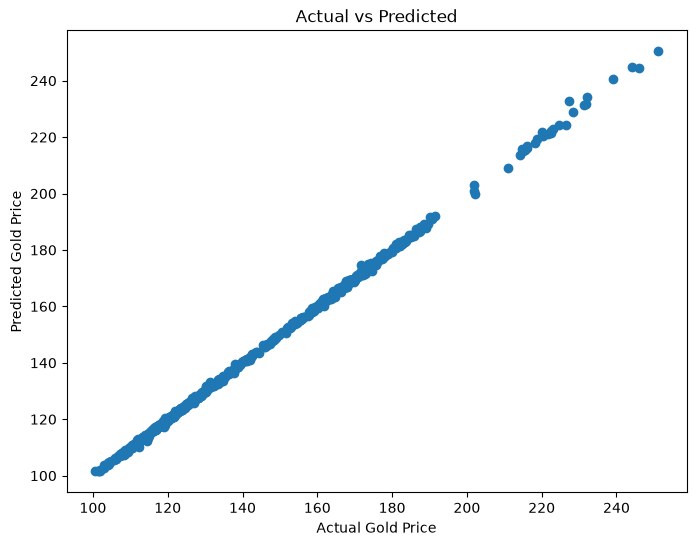

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(y_test, y_test_pred)

plt.xlabel("Actual Gold Price")
plt.ylabel("Predicted Gold Price")
plt.title("Actual vs Predicted")

plt.show()

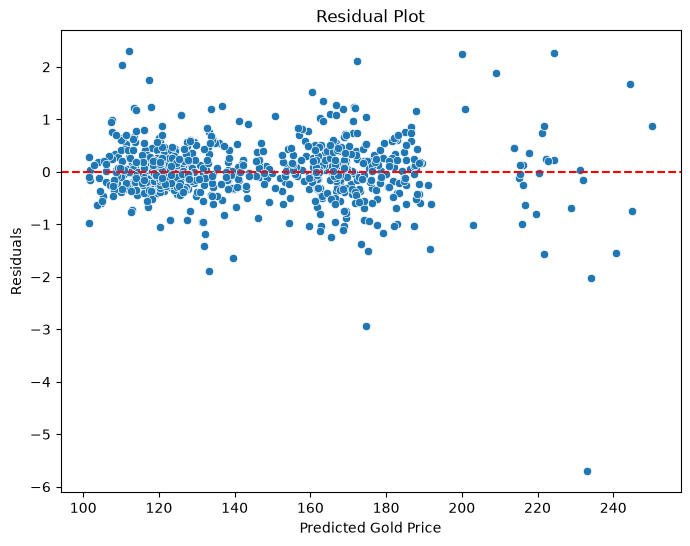

In [40]:
residuals = y_test - y_test_pred

plt.figure(figsize=(8,6))

sns.scatterplot(
    x=y_test_pred,
    y=residuals
)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Gold Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [41]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [42]:
        lin.score(X_test, y_test),
        lin.score(X_test, y_test),

,Model,R2 Score
0,Linear Regression,0.999920
1,KNN,-0.153484
2,Decision Tree,0.998968
3,Random Forest,0.999647
4,XGBoost,0.999574


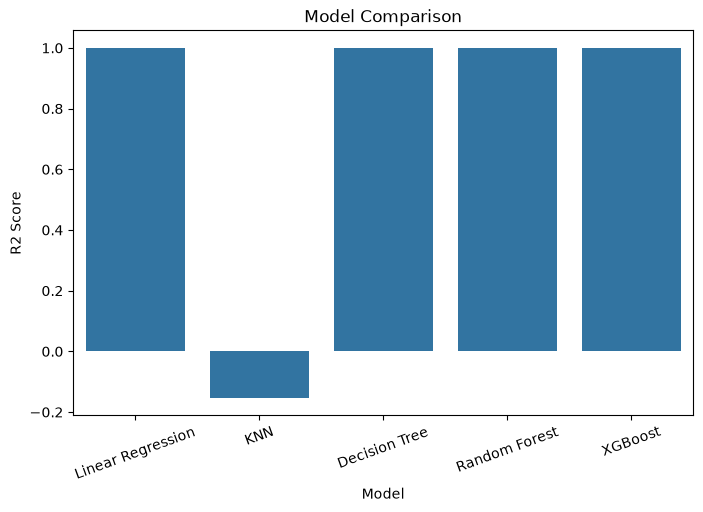

In [43]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x="Model",
    y="R2 Score"
)

plt.xticks(rotation=20)

plt.title("Model Comparison")

plt.show()

In [44]:
import joblib

joblib.dump(rf, "random_forest_model.pkl")

['random_forest_model.pkl']

In [45]:
model = joblib.load("random_forest_model.pkl")